# EDA 2 — Power Consumption of Tetouan City (UCI 849)
**Nguồn:** https://archive.ics.uci.edu/dataset/849 · **License:** CC BY 4.0 · **Paper gốc:** Salam & El Hibaoui (2018), *Comparison of Machine Learning Algorithms for the Power Consumption Prediction: Case Study of Tetouan city*, IEEE IRSEC, DOI 10.1109/IRSEC.2018.8703007.
Chuỗi phụ tải điện của ba vùng phân phối tại Tetouan, Morocco, ghi nhận mỗi 10 phút trong năm 2017, kèm nhiệt độ, độ ẩm, tốc độ gió và bức xạ. Mục tiêu: dự báo `Zone 1`, `Zone 2`, `Zone 3`.
> Cách đọc: mỗi phần có ô code, rồi ô **Nhận xét** in ra từ chính số liệu vừa tính.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from eda_utils import *
warnings.filterwarnings('ignore'); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 80
RAW = ROOT / 'data' / 'raw'
SUMMARY = {}  # các số chính, lưu ra reports/ để notebook so sánh dùng lại

## 1. Đọc dữ liệu, shape, kiểu

In [2]:
df = pd.read_csv(RAW/'Tetuan City power consumption.csv')
df['t'] = pd.to_datetime(df['DateTime'])
df = df.rename(columns={
    'Zone 1 Power Consumption': 'zone1',
    'Zone 2  Power Consumption': 'zone2',
    'Zone 3  Power Consumption': 'zone3',
})
targets = ['zone1', 'zone2', 'zone3']
exog = ['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows']
print('shape:', df.shape); display(df.head(3)); display(overview(df))
SUMMARY.update(dataset='tetouan', rows=len(df), cols=df.shape[1]-1, freq='10 phút', n_series=3,
               target='zone1, zone2, zone3')

shape: (52416, 10)


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,zone1,zone2,zone3,t
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017-01-01 00:00:00
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017-01-01 00:10:00
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017-01-01 00:20:00


,dtype,n_missing,pct_missing,n_unique
DateTime,str,0,0.0,52416
Temperature,float64,0,0.0,3437
Humidity,float64,0,0.0,4443
Wind Speed,float64,0,0.0,548
general diffuse flows,float64,0,0.0,10504
diffuse flows,float64,0,0.0,10449
zone1,float64,0,0.0,27709
zone2,float64,0,0.0,29621
zone3,float64,0,0.0,22838
t,datetime64[us],0,0.0,52416


## 2. Khoảng thời gian, lưới thời gian, missing và trùng

In [3]:
g, missing = time_gaps(df['t'], '10min'); display(pd.Series(g))
print('Dòng trùng hoàn toàn:', df.duplicated().sum(), '| NA tổng:', df.isna().sum().sum())
SUMMARY.update(start=g['start'], end=g['end'], missing_steps=g['n_missing_steps'], dup_ts=g['n_duplicated_ts'], n_na=int(df.isna().sum().sum()))

start              2017-01-01 00:00:00
end                2017-12-30 23:50:00
n_expected                       52416
n_unique                         52416
n_missing_steps                      0
n_duplicated_ts                      0
dtype: object

Dòng trùng hoàn toàn: 0 | NA tổng: 0


In [4]:
print(f"Nhận xét: có {g['n_expected']} mốc 10 phút kỳ vọng, thiếu {g['n_missing_steps']} mốc và có {g['n_duplicated_ts']} timestamp trùng. "
      f"Dữ liệu có {df.isna().sum().sum()} NA trong ô. Đây là lưới thời gian sạch, thuận lợi cho tạo cửa sổ DL và đánh giá multi-step.")

Nhận xét: có 52416 mốc 10 phút kỳ vọng, thiếu 0 mốc và có 0 timestamp trùng. Dữ liệu có 0 NA trong ô. Đây là lưới thời gian sạch, thuận lợi cho tạo cửa sổ DL và đánh giá multi-step.


## 3. Thống kê mô tả và phân phối target

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
zone1,52416.0,32344.971,7130.563,13895.696,26310.669,32265.920,37309.018,52204.395,0.229,-0.754
zone2,52416.0,21042.509,5201.466,8560.081,16980.766,20823.168,24713.718,37408.861,0.329,-0.437
zone3,52416.0,17835.406,6622.165,5935.174,13129.327,16415.117,21624.100,47598.326,1.024,1.086
Temperature,52416.0,18.810,5.815,3.247,14.410,18.780,22.890,40.010,0.197,-0.303
Humidity,52416.0,68.260,15.551,11.340,58.310,69.860,81.400,94.800,-0.625,-0.122
Wind Speed,52416.0,1.959,2.349,0.050,0.078,0.086,4.915,6.483,0.462,-1.783
general diffuse flows,52416.0,182.697,264.401,0.004,0.062,5.036,319.600,1163.000,1.307,0.403
diffuse flows,52416.0,75.028,124.211,0.011,0.122,4.456,101.000,936.000,2.457,7.003


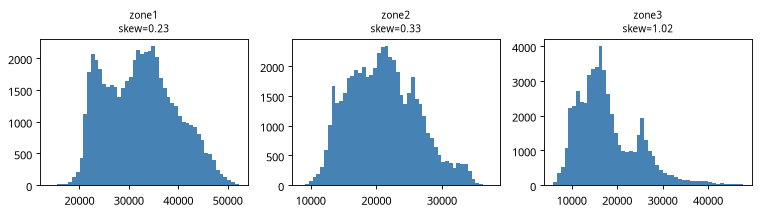

Skew log1p: {'zone1': np.float64(-0.155), 'zone2': np.float64(-0.198), 'zone3': np.float64(0.135)}


In [5]:
num = targets + exog
st = shape_stats(df[num]); display(st)
plot_dists(df, targets)
SUMMARY['target_summary'] = st.loc[targets, ['mean','50%','std','min','max','skew','kurtosis']].to_dict('index')
SUMMARY['target_mean'] = round(float(st.loc['zone1', 'mean']), 3)
SUMMARY['target_skew'] = round(float(st.loc['zone1', 'skew']), 3)
SUMMARY['target_kurt'] = round(float(st.loc['zone1', 'kurtosis']), 3)
SUMMARY['target_cv'] = round(float(st.loc['zone1', 'std'] / st.loc['zone1', 'mean']), 3)
print('Skew log1p:', {c: round(np.log1p(df[c]).skew(), 3) for c in targets})

In [6]:
print('Nhận xét: ba vùng có quy mô và phân phối khác nhau; cần scale từng target hoặc dùng loss có trọng số nếu huấn luyện multi-output. '
      'Kiểm tra log1p trước khi dùng nếu muốn giảm ảnh hưởng của các đỉnh phụ tải.')

Nhận xét: ba vùng có quy mô và phân phối khác nhau; cần scale từng target hoặc dùng loss có trọng số nếu huấn luyện multi-output. Kiểm tra log1p trước khi dùng nếu muốn giảm ảnh hưởng của các đỉnh phụ tải.


## 4. Outlier theo IQR

In [7]:
out = iqr_outliers(df[targets]); display(out)
SUMMARY['target_outlier_pct'] = float(out.loc['zone1', 'pct'])
print('Nhận xét: các điểm vượt IQR có thể là giờ cao điểm thật. Không nên xoá tự động; cần đối chiếu theo thời gian và đánh giá thêm bằng loss bền vững.')

,lower,upper,n_outliers,pct
zone1,9813.144454,53806.542424,0.0,0.000
zone2,5381.338801,36313.144751,7.0,0.013
zone3,387.165945,34366.261105,1191.0,2.272


Nhận xét: các điểm vượt IQR có thể là giờ cao điểm thật. Không nên xoá tự động; cần đối chiếu theo thời gian và đánh giá thêm bằng loss bền vững.


## 5. Xu hướng, mùa vụ và tương quan giữa ba vùng

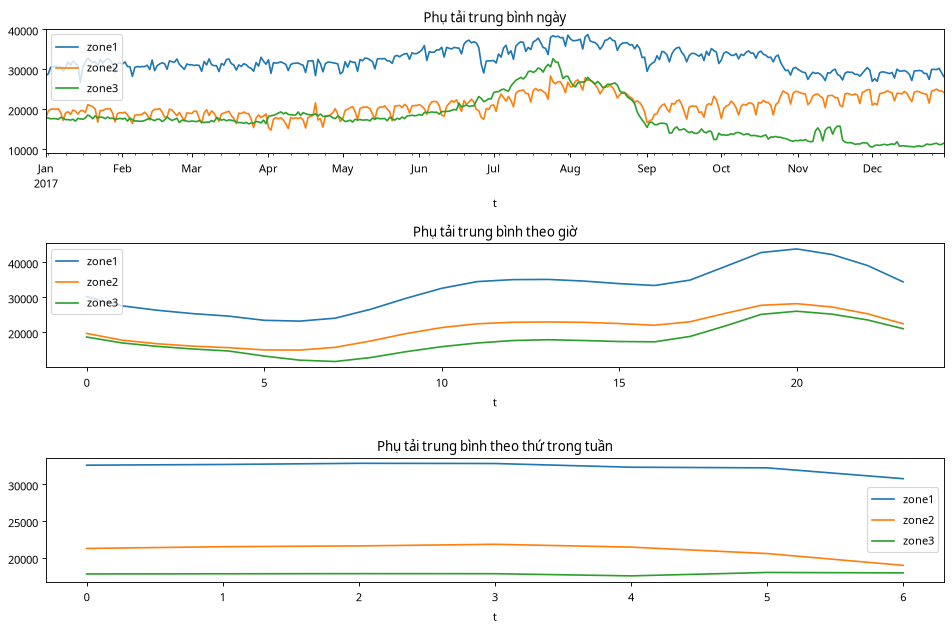

TB theo tháng:


,zone1,zone2,zone3
t,,,
1,31032.5,19394.4,17746.1
2,30985.8,18787.8,17335.0
3,31155.2,18457.9,16947.7
4,31169.8,17634.0,18593.2
5,32396.0,19977.3,17621.1
6,34605.5,20670.9,20430.9
7,35831.6,24147.9,28194.1
8,36435.2,24656.2,24648.9
9,33396.7,20180.4,14922.8


Tương quan Pearson giữa các target:


,zone1,zone2,zone3
zone1,1.000,0.835,0.751
zone2,0.835,1.000,0.571
zone3,0.751,0.571,1.000


In [8]:
hourly = df.set_index('t')[targets].resample('h').mean()
fig, ax = plt.subplots(3, 1, figsize=(12, 8))
hourly.resample('D').mean().plot(ax=ax[0], title='Phụ tải trung bình ngày')
hourly.groupby(hourly.index.hour).mean().plot(ax=ax[1], title='Phụ tải trung bình theo giờ')
hourly.groupby(hourly.index.dayofweek).mean().plot(ax=ax[2], title='Phụ tải trung bình theo thứ trong tuần')
plt.tight_layout(); plt.show()
monthly = hourly.groupby(hourly.index.month).mean(); print('TB theo tháng:'); display(monthly.round(1))
print('Tương quan Pearson giữa các target:'); display(df[targets].corr().round(3))

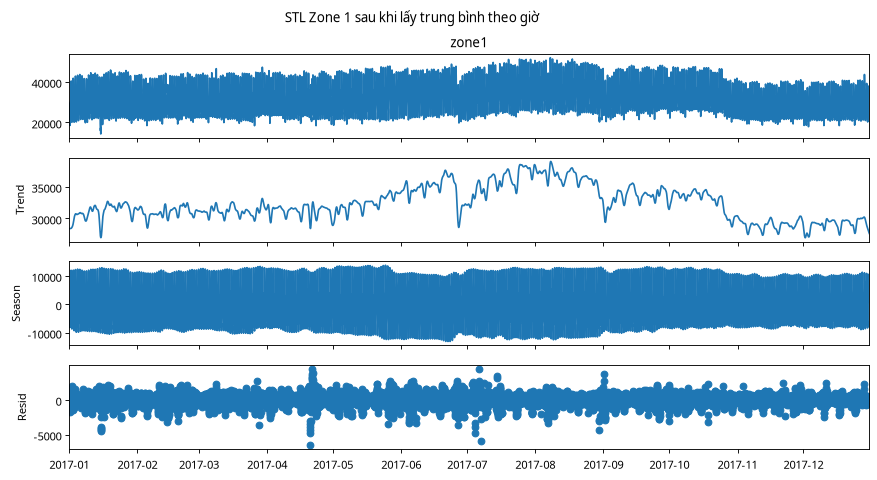

Nhận xét: sau khi quy về giờ, Zone 1 có độ mạnh mùa vụ ngày STL=0.987 và độ mạnh xu hướng=0.931. Nên kiểm tra thêm mùa vụ tuần và sự khác nhau giữa các vùng trước khi chọn window length.


In [9]:
stl = stl_strength(hourly['zone1'], period=24, title='STL Zone 1 sau khi lấy trung bình theo giờ')
SUMMARY.update(trend_strength=stl['trend_strength'], seasonal_strength=stl['seasonal_strength'])
print(f"Nhận xét: sau khi quy về giờ, Zone 1 có độ mạnh mùa vụ ngày STL={stl['seasonal_strength']} và độ mạnh xu hướng={stl['trend_strength']}. "
      'Nên kiểm tra thêm mùa vụ tuần và sự khác nhau giữa các vùng trước khi chọn window length.')

## 6. ACF/PACF và kiểm định dừng

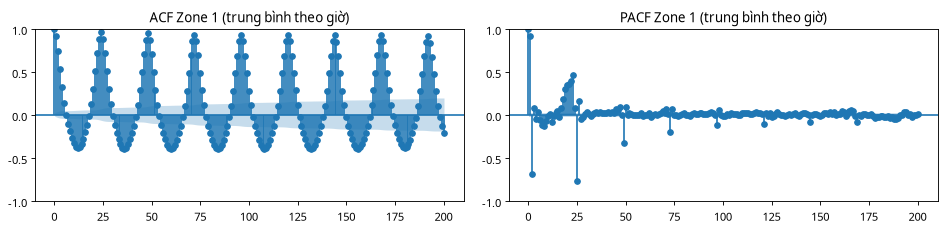

{'lag1': np.float64(0.922), 'lag3': np.float64(0.534), 'lag6': np.float64(0.005), 'lag24': np.float64(0.963), 'lag168': np.float64(0.953)}


,series,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p(bị chặn 0.01-0.1),kết luận
0,Zone 1 theo giờ,8736,-4.446,0.0002,3.389,0.01,"trái chiều: ADF nói dừng, KPSS nói không dừng ..."


Nhận xét: ACF lag1=0.922, lag24=0.963, lag168=0.953; lag 24 và 168 giúp kiểm tra mùa ngày/tuần. Kết quả ADF/KPSS chỉ là chẩn đoán; mô hình DL vẫn cần validation theo thời gian.


In [10]:
s = hourly['zone1']
acf_pacf(s, lags=200, title='Zone 1 (trung bình theo giờ)')
ac = autocorrs(s, [1, 3, 6, 24, 168]); print(ac); SUMMARY['acf'] = ac
res = pd.DataFrame([stationarity(s, 'Zone 1 theo giờ')]); display(res)
SUMMARY['stationarity'] = res.set_index('series')['kết luận'].to_dict()
print(f"Nhận xét: ACF lag1={ac['lag1']}, lag24={ac['lag24']}, lag168={ac['lag168']}; lag 24 và 168 giúp kiểm tra mùa ngày/tuần. "
      'Kết quả ADF/KPSS chỉ là chẩn đoán; mô hình DL vẫn cần validation theo thời gian.')

## 7. Tương quan với biến ngoại sinh

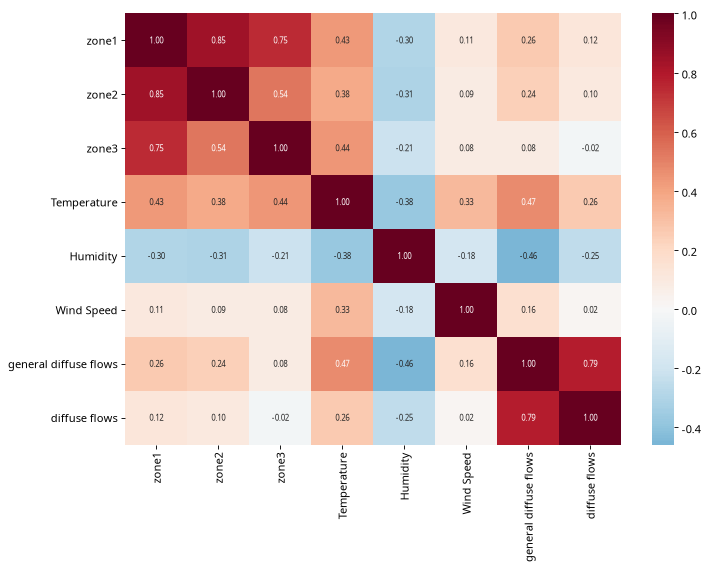

Temperature              0.433
Humidity                -0.300
general diffuse flows    0.261
diffuse flows            0.125
Wind Speed               0.107
Name: zone1, dtype: float64

Nhận xét: các ngoại sinh liên quan Zone 1 mạnh nhất theo Spearman: Temperature=0.43, Humidity=-0.30, general diffuse flows=0.26. Khi dự báo nhiều bước, chỉ dùng ngoại sinh thực sự có sẵn hoặc dùng giá trị dự báo/lag của chúng.


In [11]:
corr = df[targets + exog].corr(method='spearman')
plt.figure(figsize=(10, 7)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size':7}); plt.show()
c = corr['zone1'].drop(targets).sort_values(key=abs, ascending=False); display(c.round(3))
SUMMARY['top_exog'] = c.round(3).head(3).to_dict()
print(f"Nhận xét: các ngoại sinh liên quan Zone 1 mạnh nhất theo Spearman: {', '.join(f'{k}={v:.2f}' for k,v in c.head(3).items())}. "
      'Khi dự báo nhiều bước, chỉ dùng ngoại sinh thực sự có sẵn hoặc dùng giá trị dự báo/lag của chúng.')

In [12]:
import json; (ROOT/'reports').mkdir(exist_ok=True)
json.dump(SUMMARY, open(ROOT/'reports'/f"summary_{SUMMARY['dataset']}.json", 'w'), ensure_ascii=False, indent=1, default=str)
SUMMARY

{'dataset': 'tetouan',
 'rows': 52416,
 'cols': 9,
 'freq': '10 phút',
 'n_series': 3,
 'target': 'zone1, zone2, zone3',
 'start': Timestamp('2017-01-01 00:00:00'),
 'end': Timestamp('2017-12-30 23:50:00'),
 'missing_steps': 0,
 'dup_ts': 0,
 'n_na': 0,
 'target_summary': {'zone1': {'mean': 32344.971,
   '50%': 32265.92,
   'std': 7130.563,
   'min': 13895.696,
   'max': 52204.395,
   'skew': 0.229,
   'kurtosis': -0.754},
  'zone2': {'mean': 21042.509,
   '50%': 20823.168,
   'std': 5201.466,
   'min': 8560.081,
   'max': 37408.861,
   'skew': 0.329,
   'kurtosis': -0.437},
  'zone3': {'mean': 17835.406,
   '50%': 16415.117,
   'std': 6622.165,
   'min': 5935.174,
   'max': 47598.326,
   'skew': 1.024,
   'kurtosis': 1.086}},
 'target_mean': 32344.971,
 'target_skew': 0.229,
 'target_kurt': -0.754,
 'target_cv': 0.22,
 'target_outlier_pct': 0.0,
 'trend_strength': np.float64(0.931),
 'seasonal_strength': np.float64(0.987),
 'acf': {'lag1': np.float64(0.922),
  'lag3': np.float64(0.534